# 05 - Explain the model and check fairness

Two questions a hospital (and an interviewer) will ask:
1. **Why** does the model flag a patient? -> permutation importance + SHAP.
2. **Is it equally good for everyone?** -> recall and false-positive rate by race, gender and age.

**Inputs:** clean data, split, the gradient boosting model and the threshold from notebook 04. Everything is measured on the **test set**.

## 1. Setup

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT / "data" / "processed"
FIG = PROJECT / "reports" / "figures"
MODELS = PROJECT / "models"
SEED = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(PROCESSED / "diabetic_clean.csv", dtype={"encounter_id": str, "patient_nbr": str})
split = pd.read_csv(PROCESSED / "split.csv", dtype={"encounter_id": str})
df = df.merge(split, on="encounter_id", validate="one_to_one")

X = df.drop(columns=["encounter_id", "patient_nbr", "readmit_30", "age", "set"])
y = df["readmit_30"]
is_train = df["set"] == "train"
X_train, y_train = X[is_train], y[is_train]
X_test, y_test = X[~is_train], y[~is_train]
test_df = df[~is_train]                       # keeps the age band etc. for fairness groups

decision = json.loads((MODELS / "threshold.json").read_text())
model = joblib.load(MODELS / decision["model_file"])
THRESHOLD = decision["threshold"]

p_test = model.predict_proba(X_test)[:, 1]
flag = p_test >= THRESHOLD
print(f"Model: {decision['model']}  threshold {THRESHOLD}  test ROC-AUC {roc_auc_score(y_test, p_test):.3f}")

Model: Gradient boosting  threshold 0.18  test ROC-AUC 0.678


## 2. Permutation importance (works for any model)
Idea: shuffle one column in the test set, which breaks its link to the target, and measure how much ROC-AUC drops.
A big drop = the model relies on that column. We repeat each shuffle 5 times and average.

It works on the **original 30 columns** (the pipeline re-encodes the shuffled data), so the results are easy to read.

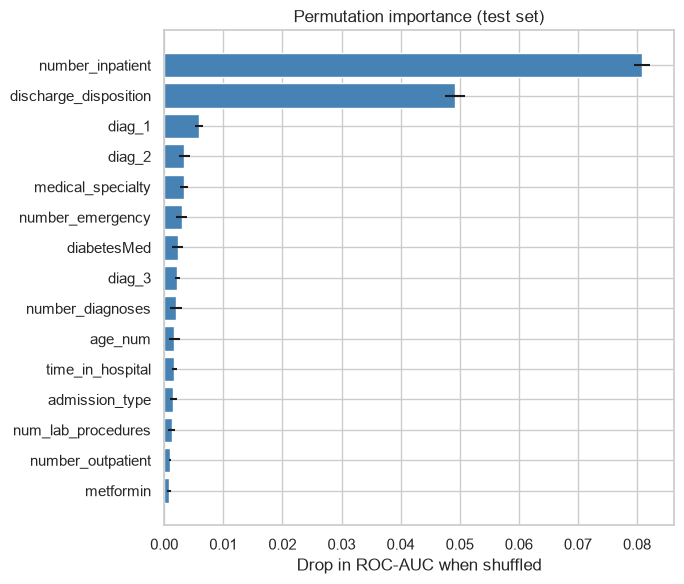

,feature,auc_drop,std
9,number_inpatient,0.0808,0.0013
27,discharge_disposition,0.0492,0.0017
10,diag_1,0.0059,0.0007
11,diag_2,0.0034,0.0009
3,medical_specialty,0.0033,0.0007
8,number_emergency,0.0030,0.0009
25,diabetesMed,0.0023,0.0009
12,diag_3,0.0022,0.0004
13,number_diagnoses,0.0020,0.0010
29,age_num,0.0017,0.0009


In [2]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=SEED)   # single process: parallel jobs hit a temp-folder bug on Windows
perm_df = (pd.DataFrame({"feature": X_test.columns,
                         "auc_drop": perm.importances_mean,
                         "std": perm.importances_std})
             .sort_values("auc_drop", ascending=False))

top = perm_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["feature"], top["auc_drop"], xerr=top["std"], color="steelblue")
ax.set(title="Permutation importance (test set)", xlabel="Drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.savefig(FIG / "05_permutation_importance.png", dpi=150)
plt.show()
perm_df.head(10).round(4)

## 3. SHAP: direction, not just size
Permutation importance says *how much* a feature matters. **SHAP** also says *which way* it pushes each patient's risk.

For one patient, SHAP splits the prediction into a sum:
`prediction = average prediction + contribution(feature 1) + contribution(feature 2) + ...`
For gradient boosting the units are **log-odds** (positive = raises risk, negative = lowers risk).

The model works on the 120 one-hot columns, so we explain those, then add the pieces of each original column back together
(e.g. all `discharge_disposition_*` columns -> `discharge_disposition`). We use a random sample of 2,000 test patients to keep it fast.

In [3]:
pre = model.named_steps["pre"]
booster = model.named_steps["model"]

num_cols = pre.transformers_[0][2]
cat_cols = pre.transformers_[1][2]
ohe = pre.named_transformers_["cat"]

# original column for each of the 120 model columns, and a readable name for each
orig_of = list(num_cols) + [c for c, cats in zip(cat_cols, ohe.categories_) for _ in cats]
nice_names = list(num_cols) + [f"{c}={v}" for c, cats in zip(cat_cols, ohe.categories_) for v in cats]
assert len(orig_of) == len(pre.get_feature_names_out())

sample = X_test.sample(2000, random_state=SEED)
Xs = pre.transform(sample)

explainer = shap.TreeExplainer(booster)
sv = explainer(Xs)
sv.feature_names = nice_names
print("SHAP values:", sv.values.shape)

SHAP values: (2000, 120)


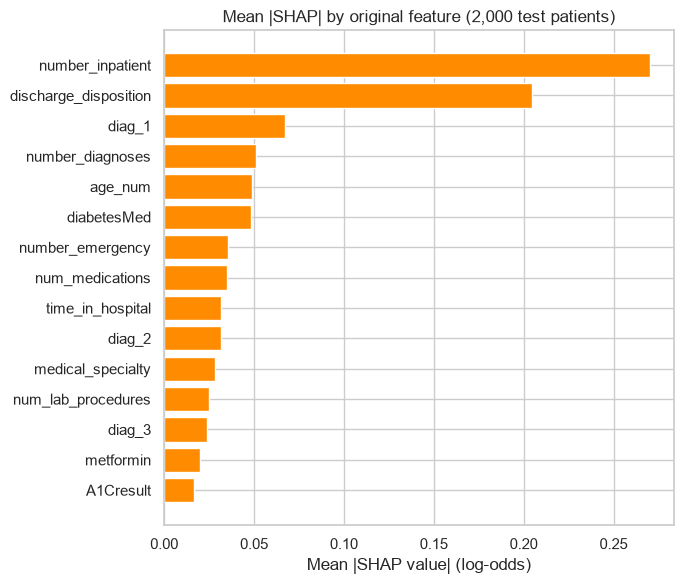

In [4]:
# add the one-hot pieces back up to the original 30 columns
shap_orig = pd.DataFrame(sv.values, columns=orig_of).T.groupby(level=0).sum().T
shap_rank = shap_orig.abs().mean().sort_values(ascending=False)

top = shap_rank.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color="darkorange")
ax.set(title="Mean |SHAP| by original feature (2,000 test patients)", xlabel="Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.savefig(FIG / "05_shap_importance.png", dpi=150)
plt.show()

**Beeswarm plot:** each dot is one patient. Position left/right = lowers/raises risk. Colour = the feature's value (red high, blue low).
Numeric features are shown in their scaled form (StandardScaler), so read the colour as "high vs low", not exact numbers.

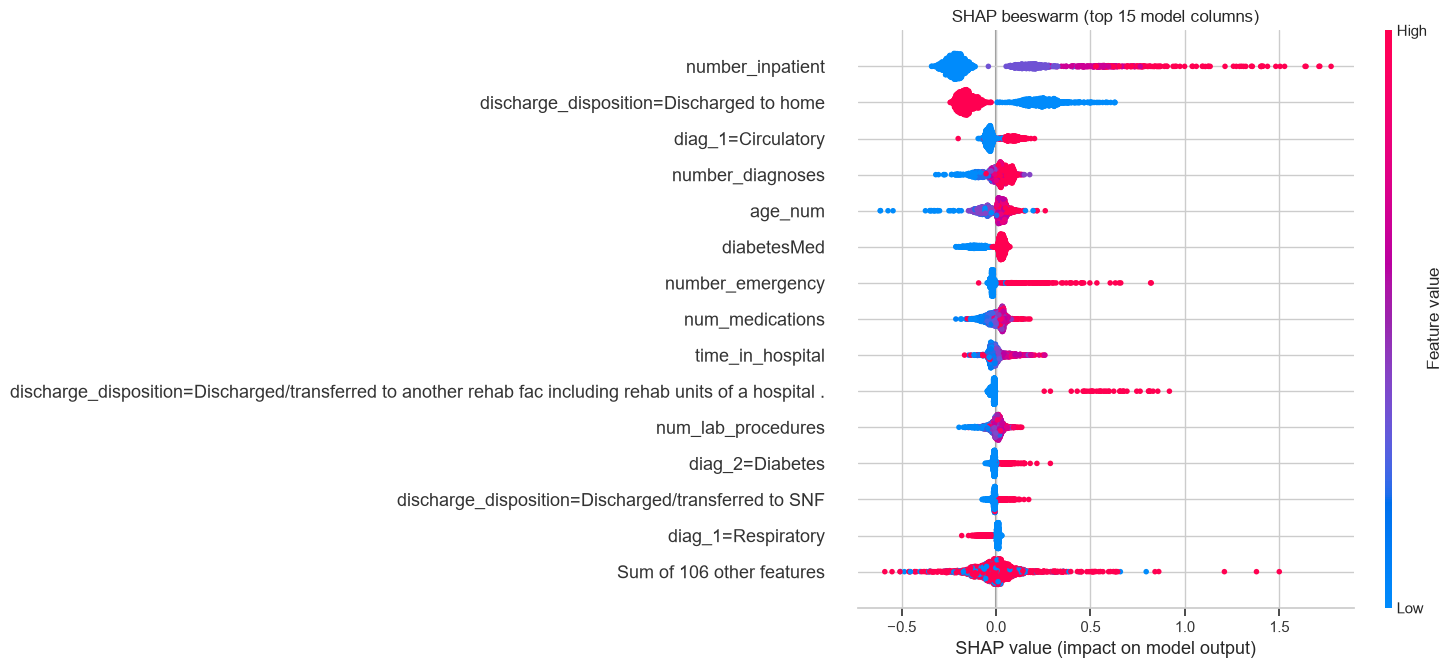

In [5]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP beeswarm (top 15 model columns)")
plt.savefig(FIG / "05_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

### Explaining one patient
The highest-risk patient in the sample. This is the view a care coordinator could use: *why* was this person flagged?
We swap the scaled numbers back to the real values so the labels read naturally (e.g. `number_inpatient = 1`).

The plot is in **log-odds**: it starts at the average patient `E[f(X)]`, each bar adds or subtracts, and ends at this patient's `f(x)`.
To turn log-odds into a probability use the sigmoid: $p = 1 / (1 + e^{-f(x)})$. The code prints both so you can check they match.

Average patient: log-odds -2.18 -> probability 10.2%
This patient:    log-odds 0.37 -> probability 59.2%
Model's predict_proba (should match): 59.2%


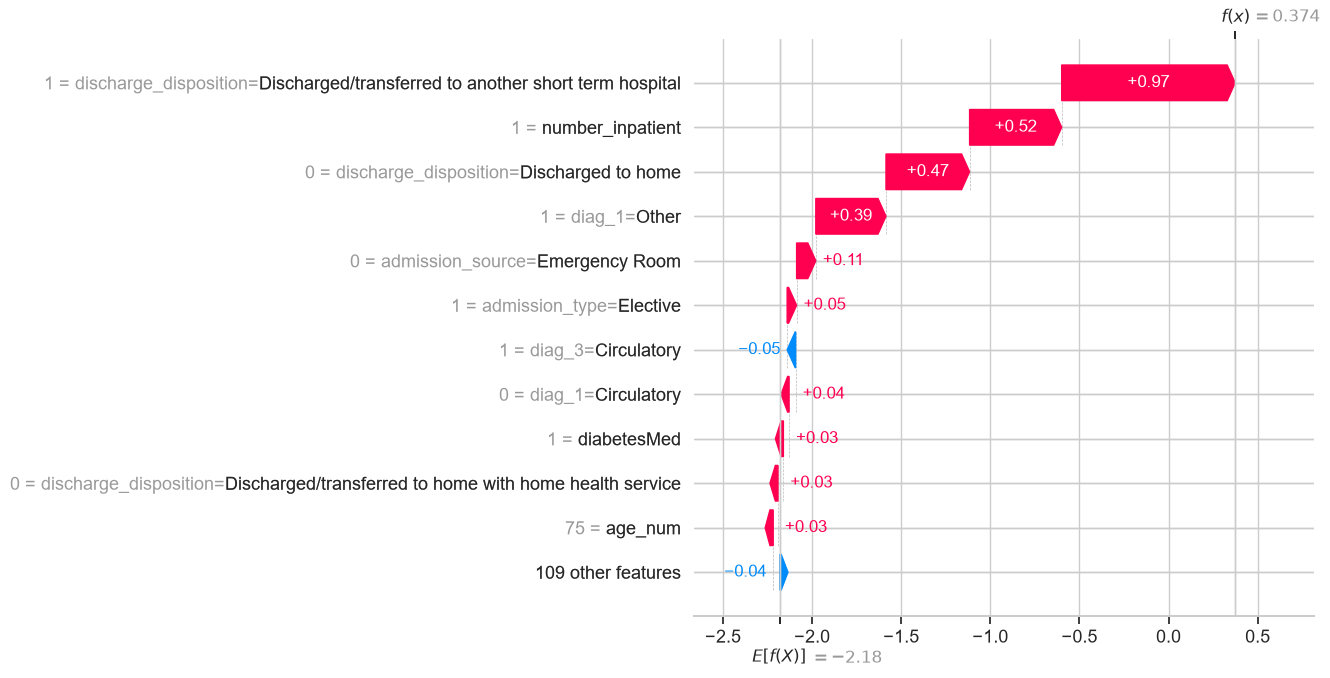

In [6]:
i = int(np.argmax(booster.predict_proba(Xs)[:, 1]))
display_data = Xs[i].copy()
display_data[: len(num_cols)] = sample.iloc[i][list(num_cols)].to_numpy()

one = shap.Explanation(values=sv.values[i], base_values=sv.base_values[i],
                       data=display_data, feature_names=nice_names)
log_odds = sv.base_values[i] + sv.values[i].sum()          # = f(x) on the plot
print(f"Average patient: log-odds {sv.base_values[i]:.2f} -> probability {1 / (1 + np.exp(-sv.base_values[i])):.1%}")
print(f"This patient:    log-odds {log_odds:.2f} -> probability {1 / (1 + np.exp(-log_odds)):.1%}")
print(f"Model's predict_proba (should match): {booster.predict_proba(Xs[i:i+1])[0, 1]:.1%}")
shap.plots.waterfall(one, max_display=12, show=False)
plt.savefig(FIG / "05_shap_one_patient.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Fairness check at the chosen threshold
For each group we compare:
- **Recall (true positive rate)**: of the patients who *were* readmitted, what share did we flag? Low recall for a group = that group's
  at-risk patients are missed more often (**they lose out on follow-up care**).
- **False positive rate (FPR)**: of the patients who were *not* readmitted, what share did we flag anyway? High FPR = unnecessary calls.

Comparing recall across groups is the **equal opportunity** idea. Small groups give noisy numbers, so we add a 95% confidence interval
(Wilson method) and mark groups with fewer than 100 readmitted patients.

**Wilson interval** for a proportion $\hat p$ from $n$ cases ($z = 1.96$):
$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
It behaves better than the textbook $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$ when $n$ is small or $\hat p$ is near 0 or 1.

In [7]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - half, centre + half)

AGE_GROUP = {"[0-10)": "<50", "[10-20)": "<50", "[20-30)": "<50", "[30-40)": "<50", "[40-50)": "<50",
             "[50-60)": "50-69", "[60-70)": "50-69", "[70-80)": "70+", "[80-90)": "70+", "[90-100)": "70+"}

fair = pd.DataFrame({"y": y_test.to_numpy(), "flag": flag,
                     "race": test_df["race"].to_numpy(),
                     "gender": test_df["gender"].to_numpy(),
                     "age_group": pd.Categorical(test_df["age"].map(AGE_GROUP),
                                                 categories=["<50", "50-69", "70+"], ordered=True)})

def group_metrics(data, by):
    rows = []
    for g, d in data.groupby(by, observed=True):   # observed=True: skip empty category levels
        pos, neg = d[d["y"] == 1], d[d["y"] == 0]
        tp, fp = int(pos["flag"].sum()), int(neg["flag"].sum())
        lo, hi = wilson(tp, len(pos))
        rows.append({"attribute": by, "group": g, "n": len(d), "readmitted": len(pos),
                     "base_rate": d["y"].mean(), "flagged_pct": d["flag"].mean(),
                     "recall": tp / len(pos) if len(pos) else np.nan, "recall_lo": lo, "recall_hi": hi,
                     "fpr": fp / len(neg), "small_group": len(pos) < 100})
    return pd.DataFrame(rows)

fairness = pd.concat([group_metrics(fair, a) for a in ["race", "gender", "age_group"]], ignore_index=True)
fairness.round(3)

,attribute,group,n,readmitted,base_rate,flagged_pct,recall,recall_lo,recall_hi,fpr,small_group
0,race,AfricanAmerican,3687,418,0.113,0.133,0.278,0.237,0.322,0.115,False
1,race,Asian,100,8,0.080,0.040,0.125,0.022,0.471,0.033,True
2,race,Caucasian,14974,1744,0.116,0.123,0.274,0.254,0.295,0.103,False
3,race,Hispanic,415,45,0.108,0.130,0.467,0.329,0.609,0.089,True
4,race,Other,262,19,0.073,0.088,0.316,0.154,0.540,0.070,True
5,race,Unknown,430,29,0.067,0.065,0.138,0.055,0.306,0.060,True
6,gender,Female,10616,1192,0.112,0.119,0.268,0.243,0.293,0.100,False
7,gender,Male,9252,1071,0.116,0.127,0.287,0.260,0.314,0.106,False
8,age_group,<50,3170,324,0.102,0.133,0.361,0.311,0.415,0.107,False
9,age_group,50-69,7773,832,0.107,0.118,0.287,0.258,0.319,0.098,False


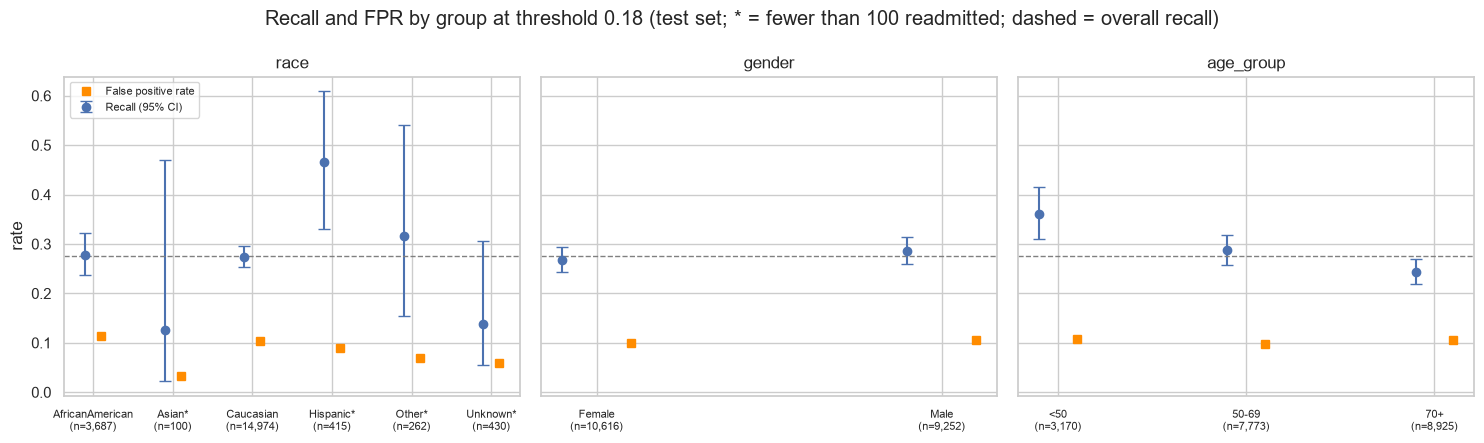

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, attr in zip(axes, ["race", "gender", "age_group"]):
    d = fairness[fairness["attribute"] == attr].reset_index(drop=True)
    x = np.arange(len(d))
    ax.errorbar(x - 0.1, d["recall"], yerr=[d["recall"] - d["recall_lo"], d["recall_hi"] - d["recall"]],
                fmt="o", capsize=4, label="Recall (95% CI)")
    ax.plot(x + 0.1, d["fpr"], "s", color="darkorange", label="False positive rate")
    labels = [f"{g}{'*' if s else ''}\n(n={n:,})" for g, n, s in zip(d["group"], d["n"], d["small_group"])]
    ax.set_xticks(x, labels, fontsize=8)
    ax.axhline(decision["test"]["recall"], ls="--", color="grey", lw=1)
    ax.set_title(attr)
axes[0].set_ylabel("rate")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(f"Recall and FPR by group at threshold {THRESHOLD} (test set; * = fewer than 100 readmitted; dashed = overall recall)")
plt.tight_layout()
plt.savefig(FIG / "05_fairness.png", dpi=150)
plt.show()

**Gaps** among groups with at least 100 readmitted patients (small groups excluded because their numbers are too noisy to compare):

In [9]:
big = fairness[~fairness["small_group"]]
gaps = big.groupby("attribute").agg(
    recall_min=("recall", "min"), recall_max=("recall", "max"),
    fpr_min=("fpr", "min"), fpr_max=("fpr", "max"))
gaps["recall_gap"] = gaps["recall_max"] - gaps["recall_min"]
gaps["fpr_gap"] = gaps["fpr_max"] - gaps["fpr_min"]
gaps.round(3)

,recall_min,recall_max,fpr_min,fpr_max,recall_gap,fpr_gap
attribute,,,,,,
age_group,0.244,0.361,0.098,0.107,0.117,0.009
gender,0.268,0.287,0.100,0.106,0.019,0.006
race,0.274,0.278,0.103,0.115,0.003,0.012


**Why do gaps appear even without any intent to discriminate?** With one threshold for everyone, a group whose patients have
higher predicted risk overall gets flagged more, so both its recall *and* its FPR rise together. Look at `base_rate` and `flagged_pct`
alongside recall: if a group's recall is low, is it because the model ranks that group badly, or because that group simply has fewer
prior hospital visits recorded?

## 5. Experiment: what if we remove `race` from the model?
"Fairness through unawareness" means dropping the sensitive column. We retrain the same model without `race`
(same settings via `clone`) and compare overall AUC and recall by race. If nothing changes much, the model was not leaning on race directly,
although other columns can still act as proxies.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cat_no_race = [c for c in cat_cols if c != "race"]
model_nr = Pipeline([
    ("pre", ColumnTransformer([
        ("num", StandardScaler(), list(num_cols)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_no_race)])),
    ("model", clone(booster)),
])
model_nr.fit(X_train.drop(columns="race"), y_train)
p_nr = model_nr.predict_proba(X_test.drop(columns="race"))[:, 1]

print(f"ROC-AUC with race:    {roc_auc_score(y_test, p_test):.4f}")
print(f"ROC-AUC without race: {roc_auc_score(y_test, p_nr):.4f}")

fair_nr = fair.assign(flag=p_nr >= THRESHOLD)
compare = (group_metrics(fair, "race")[["group", "readmitted", "recall", "fpr"]]
           .merge(group_metrics(fair_nr, "race")[["group", "recall", "fpr"]], on="group",
                  suffixes=("_with_race", "_without_race")))
compare.round(3)

ROC-AUC with race:    0.6782
ROC-AUC without race: 0.6783


,group,readmitted,recall_with_race,fpr_with_race,recall_without_race,fpr_without_race
0,AfricanAmerican,418,0.278,0.115,0.287,0.114
1,Asian,8,0.125,0.033,0.125,0.033
2,Caucasian,1744,0.274,0.103,0.281,0.100
3,Hispanic,45,0.467,0.089,0.422,0.073
4,Other,19,0.316,0.070,0.263,0.078
5,Unknown,29,0.138,0.060,0.138,0.062


## 6. Limitations
- SHAP and permutation importance explain the *model*, not causes. "Prior inpatient visits raise predicted risk" does not mean
  visits *cause* readmission; they mark sicker patients.
- Asian, Hispanic, Other and some age groups have few readmitted patients in the test set, so their fairness numbers have wide intervals.
- Fairness was checked for one threshold and one metric family (recall/FPR); other definitions (e.g. calibration by group) can disagree.